In [1]:
import numpy as np
import pandas as pd

input_file = "winequality-red.csv"
df = pd.read_csv(input_file)
df.shape

(1599, 12)

In [2]:
def make_features(df):
    X = df.drop(["quality"], axis=1).copy()
    X["so2_ratio"] = X["free sulfur dioxide"] / X["total sulfur dioxide"]
    X["alc_sulph"] = X["alcohol"] * X["sulphates"]
    X["alc_va"] = X["alcohol"] / X["volatile acidity"]
    X["log_sulph"] = np.log(X["sulphates"])
    X["log_chl"] = np.log(X["chlorides"])
    X["log_tso2"] = np.log(X["total sulfur dioxide"])
    X["acid_total"] = X["fixed acidity"] + X["volatile acidity"] + X["citric acid"]
    return X

wine_base = df.drop(["quality"], axis=1)
wine_prepared = make_features(df)
wine_labels = df["quality"].copy()
wine_prepared.shape

(1599, 18)

In [3]:
def display_scores(scores):
    print("Scores:", scores)
    print("Mean:", scores.mean())
    print("Standard deviation:", scores.std())

In [4]:
# 1) 모델 비교: 원본 특성 vs 내 특성, 여러 회귀 모델 (10-fold RMSE)
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor

def rmse_cv(model, X):
    return np.sqrt(-cross_val_score(model, X, wine_labels, scoring="neg_mean_squared_error", cv=10)).mean()

models = {
    "LinearRegression": LinearRegression(),
    "SGD": make_pipeline(StandardScaler(), SGDRegressor(random_state=42)),
    "SVR": make_pipeline(StandardScaler(), SVR()),
    "DecisionTree": DecisionTreeRegressor(max_depth=5, random_state=42),
    "RandomForest": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "ExtraTrees": ExtraTreesRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "GradientBoosting": GradientBoostingRegressor(random_state=42),
}
for name, model in models.items():
    print(f"{name:18s} 원본 {rmse_cv(model, wine_base):.4f}   내 특성 {rmse_cv(model, wine_prepared):.4f}")

LinearRegression   원본 0.6586   내 특성 0.6446
SGD                원본 0.6591   내 특성 0.6528


SVR                원본 0.6481   내 특성 0.6511
DecisionTree       원본 0.6989   내 특성 0.7060


RandomForest       원본 0.6483   내 특성 0.6528


ExtraTrees         원본 0.6492   내 특성 0.6503


GradientBoosting   원본 0.6521   내 특성 0.6514


In [5]:
# 2) 하이퍼파라미터 탐색 (Grid Search, 10-fold): SVR 과 RandomForest
from sklearn.model_selection import GridSearchCV

svr_search = GridSearchCV(make_pipeline(StandardScaler(), SVR()),
                          {"svr__C": [0.3, 1, 3], "svr__gamma": [0.01, 0.03, "scale"], "svr__epsilon": [0.1, 0.3]},
                          cv=10, scoring="neg_mean_squared_error", n_jobs=-1)
svr_search.fit(wine_prepared, wine_labels)
print("SVR", svr_search.best_params_, np.sqrt(-svr_search.best_score_))

rf_search = GridSearchCV(RandomForestRegressor(n_estimators=300, random_state=42),
                         {"max_features": [0.33, 0.5, 1.0], "min_samples_leaf": [1, 2, 5]},
                         cv=10, scoring="neg_mean_squared_error", n_jobs=-1)
rf_search.fit(wine_prepared, wine_labels)
print("RF ", rf_search.best_params_, np.sqrt(-rf_search.best_score_))

SVR {'svr__C': 0.3, 'svr__epsilon': 0.3, 'svr__gamma': 0.03} 0.6436099789459416


RF  {'max_features': 0.33, 'min_samples_leaf': 5} 0.6401457208078694


In [6]:
# 3) 최종 모델: 튜닝한 SVR·RandomForest + ExtraTrees 를 Voting
from sklearn.ensemble import VotingRegressor

final_reg = VotingRegressor([
    ("svr", svr_search.best_estimator_),
    ("rf", RandomForestRegressor(n_estimators=500, random_state=42, **rf_search.best_params_)),
    ("et", ExtraTreesRegressor(n_estimators=800, max_features=0.5, min_samples_leaf=2, random_state=42))])

In [7]:
final_scores = cross_val_score(final_reg, wine_prepared, wine_labels, scoring="neg_mean_squared_error", cv=10)
final_rmse_scores = np.sqrt(-final_scores)
display_scores(final_rmse_scores)

Scores: [0.61108184 0.59311975 0.68144804 0.65325591 0.54478691 0.72980352
 0.6384983  0.63381973 0.59581499 0.67350174]
Mean: 0.6355130727679026
Standard deviation: 0.049971681044635625


In [8]:
np.mean(final_rmse_scores)

np.float64(0.6355130727679026)

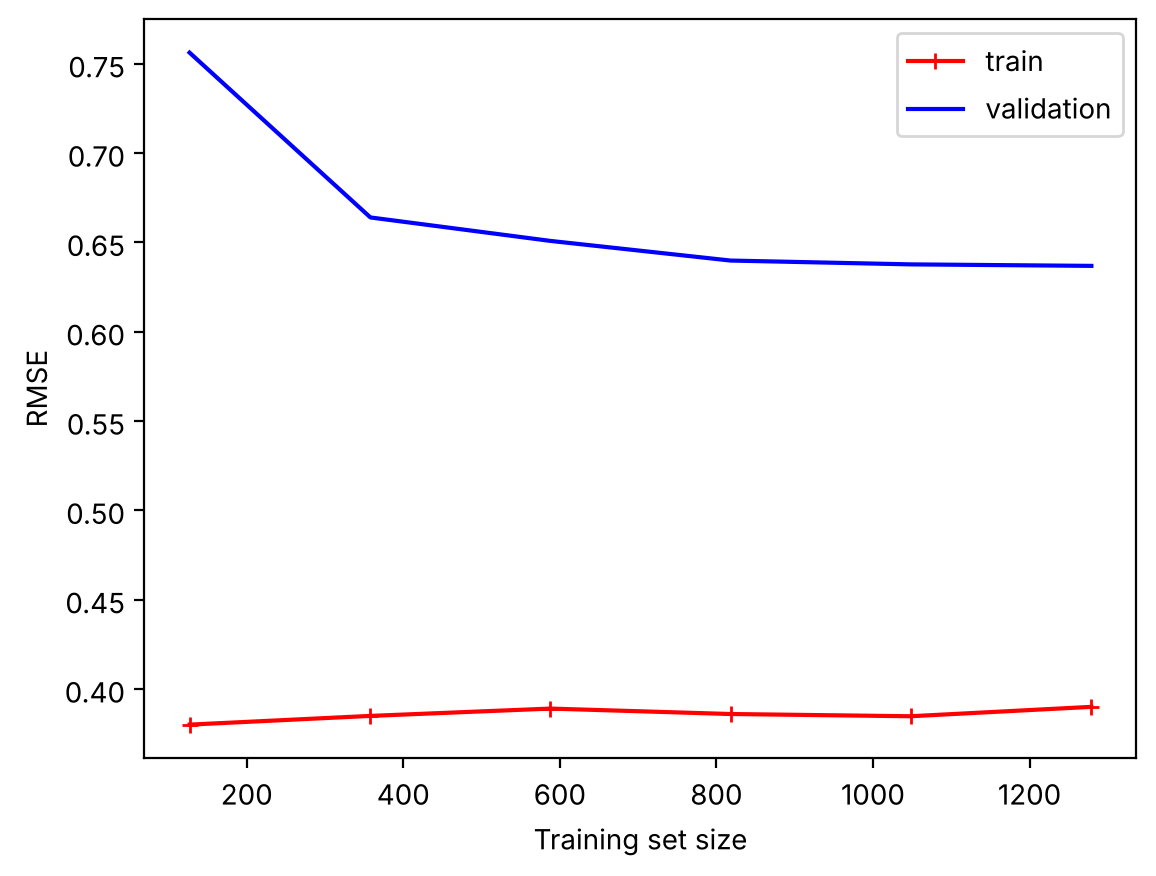

In [9]:
# 학습 곡선: 학습 데이터 양에 따른 학습/검증 RMSE
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

sizes, train_sc, val_sc = learning_curve(final_reg, wine_prepared, wine_labels, cv=5, scoring="neg_mean_squared_error",
                                         train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1)
plt.plot(sizes, np.sqrt(-train_sc.mean(axis=1)), "r-+", label="train")
plt.plot(sizes, np.sqrt(-val_sc.mean(axis=1)), "b-", label="validation")
plt.xlabel("Training set size"); plt.ylabel("RMSE"); plt.legend(); plt.show()